In [2]:
import time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42

In [3]:
df = pd.read_csv("H2.csv")
print(df.shape)
print(df["IsCanceled"].value_counts(normalize=True))
df.head()

(79330, 31)
IsCanceled
0    0.58273
1    0.41727
Name: proportion, dtype: float64


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


In [4]:
#Temporary preprocessing to get a clean X and y for the pipeline. 
data = df.copy()

# 1) Drop columns that would leak the answer or are unknown at booking time
leak_cols = ["ReservationStatus", "ReservationStatusDate", "AssignedRoomType", "BookingChanges"]
# 2) Drop ID-like columns with too many values (teammates will handle them properly)
id_cols = ["Country", "Agent", "Company"]
data = data.drop(columns=leak_cols + id_cols)

# 3) Fix columns that need converting
month_map = {m: i for i, m in enumerate(
    ["January","February","March","April","May","June","July",
     "August","September","October","November","December"], start=1)}
data["ArrivalDateMonth"] = data["ArrivalDateMonth"].map(month_map)
data["Children"] = pd.to_numeric(data["Children"], errors="coerce")

# 4) Turn text columns into 0/1 columns
data = pd.get_dummies(data, drop_first=True, dtype=float)

y = data["IsCanceled"]
X = data.drop(columns=["IsCanceled"])
print(X.shape)

(79330, 43)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(X_train.shape, X_test.shape)

(63464, 43) (15866, 43)


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

nb_base = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("nb", GaussianNB())
])

start = time.time()
nb_base.fit(X_train, y_train)
base_time = time.time() - start

base_cv = cross_val_score(nb_base, X_train, y_train, cv=cv, scoring="f1")
print("Baseline CV F1:", base_cv.mean().round(4), "+/-", base_cv.std().round(4))
print("Training time:", round(base_time, 3), "sec")

Baseline CV F1: 0.6361 +/- 0.0086
Training time: 0.205 sec


In [7]:
pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("power", PowerTransformer()),
    ("nb", GaussianNB())
])

param_grid = {
    "power": ["passthrough", PowerTransformer()],
    "nb__var_smoothing": np.logspace(-11, -1, 11)
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)

start = time.time()
grid.fit(X_train, y_train)
tune_time = time.time() - start

print("Best settings:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 4))
print("Tuning time:", round(tune_time, 1), "sec")

Best settings: {'nb__var_smoothing': np.float64(1e-05), 'power': 'passthrough'}
Best CV F1: 0.6635
Tuning time: 33.1 sec


In [8]:
def evaluate(model, name):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    }

best_nb = grid.best_estimator_
results = pd.DataFrame([evaluate(nb_base, "GaussianNB baseline"),
                        evaluate(best_nb, "GaussianNB tuned")]).round(4)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,GaussianNB baseline,0.5915,0.5062,0.8621,0.6378,0.7745
1,GaussianNB tuned,0.6818,0.5927,0.7585,0.6654,0.7816


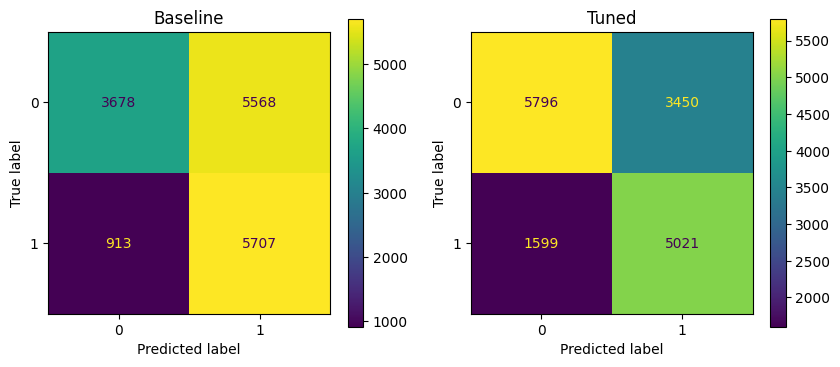

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, model, title in zip(axes, [nb_base, best_nb], ["Baseline", "Tuned"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test))).plot(ax=ax)
    ax.set_title(title)
plt.show()